# Sine steering
- We found an effect on steering helix face angles vs. hydrophobicity, however, we also saw that this is mostly attributable to the sine component of the angle
- We want to now figure out whether a residue's hydrophobicity is somehow related to the sin components of neighboring residues, because this would increase our confidence that this feature is indeed an angle, while reducing the influence of confounds. 

In [1]:
import json

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from tqdm.auto import tqdm
from transformers import AutoTokenizer, EsmForMaskedLM

from biomanifolds import config, theme
from biomanifolds.angle_study import linear_fits, samples
from biomanifolds.datasets import swissprot
from biomanifolds.labels import af2_structure_labels

theme.use()  # Nunito fonts and the project defaults

LAYERS = [30]
MODEL = "facebook/esm2_t30_150M_UR50D"
AA = "ACDEFGHIKLMNPQRSTVWY"  # order of the saved amino-acid log-probabilities
SOURCE_ANGLES = [0, 90, 180, -90]  # centres of the source bins, degrees
BIN_WIDTH = 5  # degrees
N_PER_BIN = 5000  # residues per source bin, one per protein
TARGETS = np.arange(-180, 180, 5)  # target angles, degrees
CONTROL_OFFSETS = [45, 90, 180, -90]  # random-vector controls, with the norm of the steering edit to source + offset
OUT_DIR = config.data_path("steering") / "nb05"  # results of this notebook
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Encoder of the angle for each layer, on the train helix residues of notebook 2 (ordinary least squares, one row per residue):
# h ~ a + cos(theta) w_cos + sin(theta) w_sin, with a = encoder["intercept"] (640,) and (w_cos, w_sin) = encoder["coefficients"] (2, 640)
train_helix = samples.train_helix_residues()
theta_train = np.deg2rad(train_helix["helix_face"].to_numpy())
cos_sin_train = np.column_stack([np.cos(theta_train), np.sin(theta_train)])  # (train residues, 2)
encoder = {layer: linear_fits.fit_ols(cos_sin_train, samples.train_helix_embeddings(layer, train_helix)) for layer in LAYERS}
del train_helix, theta_train, cos_sin_train


def h_pred(t, layer):
    """h_pred(t) = a + cos(t) w_cos + sin(t) w_sin for angles t (radians, any shape): (..., 640)."""
    t = np.asarray(t)
    return linear_fits.predict(encoder[layer], np.stack([np.cos(t), np.sin(t)], -1))


# ESM-2 with its amino-acid head, to read the logits at the masked residue
device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = EsmForMaskedLM.from_pretrained(MODEL, attn_implementation="sdpa").eval().to(device)

# All test proteins
sequences = pl.read_parquet(swissprot.swissprot_dir() / "swissprot.parquet", columns=["accession", "sequence"])
splits = pl.read_parquet(swissprot.swissprot_dir() / "splits" / "splits.parquet", columns=["accession", "split"])
test_proteins = sequences.join(splits.filter(pl.col("split") == "test"), on="accession").select("accession", "sequence").sort("accession")
test_proteins

(null): No such file or directory


(null): No such file or directory


Loading weights:   0%|          | 0/491 [00:00<?, ?it/s]

accession,sequence
str,str
"""A0A017TC06""","""MIDASSLKALVRRAEGGLVEALGLRPLQLD…"
"""A0A023PXA5""","""MLLSELVATASSLPYTAISIHNNCRVPAAR…"
"""A0A023PXB0""","""MFINGFVNYPVRTPPNDLLQVVLHGFLRCP…"
"""A0A023PXB5""","""MFALIISSKGKTSGFFFNSSFSSSALVGIA…"
"""A0A023PXC2""","""MLPLCLTFLSFFLSLGGSFKAVMTKEEADG…"
…,…
"""X0JZ91""","""MIASIRTTRRLSNYNSVIPPPEPLNTDPDM…"
"""X1WER2""","""MATVEELKLRIRELENELIKSKQKQSDAEH…"
"""X4Y2L4""","""MKEIAVTIDDKNVIASVSESFHGVAFDASL…"


## Hydrophobicity difference of the neighbours per helix face angle
Let $D_i = H(x_{i+1}) - H(x_{i-1})$, with $H$ the Eisenberg consensus scale. In an ideal alpha helix, each residue turns by about 100°, so the neighbours of a residue at angle $\theta$ are at $\theta \pm 100°$. If $H \approx \cos\theta$, then $D \approx \cos(\theta + 100°) - \cos(\theta - 100°) = -2 \sin(100°) \sin\theta$: $D$ should follow $-\sin\theta$.

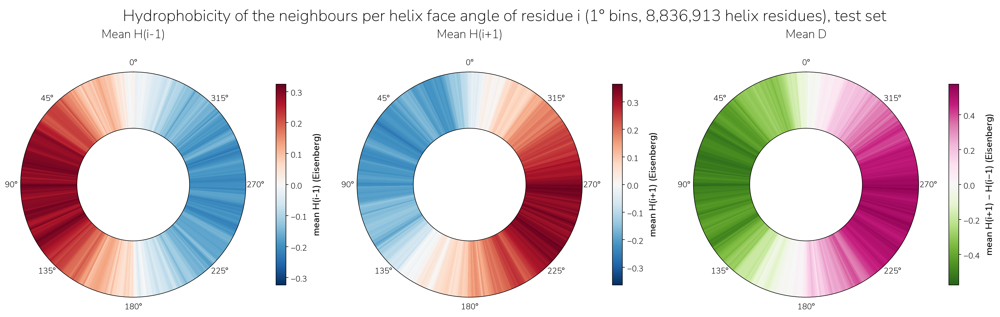

In [2]:
# Mean H(x_{i-1}), H(x_{i+1}) and D = H(x_{i+1}) - H(x_{i-1}) per helix face angle of residue i, over all helix residues of the test proteins:
# H is the Eisenberg hydrophobicity (consensus scale); the neighbours are the sequence neighbours, in or out of the helix
EISENBERG = dict(zip("ARNDCQEGHILKMFPSTWYV", [0.62, -2.53, -0.78, -0.90, 0.29, -0.85, -0.74, 0.48, -0.40, 1.38,
                                                1.06, -1.50, 0.64, 1.19, 0.12, -0.18, -0.05, 0.81, 0.26, 1.08]))
NEIGHBOUR_DIFFERENCE = plt.cm.PiYG_r  # not HYDROPHOBICITY (RdBu) or DELTA (purple-yellow): D is a different quantity
ANGLE_WIDTH = 1  # degrees

by_angle = (
    af2_structure_labels.load_labels(["accession", "i", "helix_face"])
    .filter(pl.col("helix_face").is_not_null())
    .join(test_proteins.lazy(), on="accession")
    .with_columns(**{f"H(i{k:+d})": pl.col("sequence").str.slice(pl.col("i") + k, 1).replace_strict(EISENBERG, default=None, return_dtype=pl.Float64)
                     for k in [-1, 1]})  # null if the neighbour is out of the sequence or not a standard amino acid
    .drop_nulls(["H(i-1)", "H(i+1)"])
    .group_by(angle_bin=((pl.col("helix_face") + 180) // ANGLE_WIDTH).clip(0, 360 // ANGLE_WIDTH - 1).cast(pl.Int32))
    .agg(pl.col("H(i-1)").mean(), pl.col("H(i+1)").mean(), D=(pl.col("H(i+1)") - pl.col("H(i-1)")).mean(), n=pl.len())
    .sort("angle_bin")
    .collect(engine="streaming")
)
theta = np.deg2rad(by_angle["angle_bin"].to_numpy() * ANGLE_WIDTH - 180 + ANGLE_WIDTH / 2)

# rings of 1-degree sectors, coloured by the mean of each quantity at that angle; norms centred on 0
fig, axes = plt.subplots(1, 3, figsize=(21, 7), subplot_kw={"projection": "polar"})
for ax, column, cmap in zip(axes, ["H(i-1)", "H(i+1)", "D"], [theme.HYDROPHOBICITY, theme.HYDROPHOBICITY, NEIGHBOUR_DIFFERENCE]):
    values = by_angle[column].to_numpy()
    norm = Normalize(-np.abs(values).max(), np.abs(values).max())
    ax.bar(theta, 1, bottom=1, width=np.deg2rad(ANGLE_WIDTH), color=cmap(norm(values)), linewidth=0, antialiased=False)  # no borders between sectors
    ax.set(rlim=(0, 2), yticks=[], theta_zero_location="N")  # 0 degrees at the top
    ax.grid(False)
    theme.inner_border(ax)
    fig.colorbar(ScalarMappable(norm, cmap), ax=ax, shrink=0.7, pad=0.1, label=f"mean {'H(i+1) − H(i−1)' if column == 'D' else column} (Eisenberg)")
    ax.set_title(f"Mean {column}", pad=28)  # above the 0° label
fig.suptitle(f"Hydrophobicity of the neighbours per helix face angle of residue i ({ANGLE_WIDTH}° bins, {by_angle['n'].sum():,} helix residues), test set")
plt.tight_layout()
plt.show()

## Masking the neighbours: does the angle of residue $i$ inform the model's predicted hydrophobicity of $i \pm 1$?
At $\theta = 60°$, the neighbours are at $160°$ ($i+1$, outer face) and $-40°$ ($i-1$, inner face); at $\theta = -60°$ the opposite. From the rings above, we expect $D > 0$ at $-60°$ and $D < 0$ at $60°$.
- Residues: 2 bins of 5 degrees of the test set (60 and -60 degrees), 5000 residues per bin, one residue per protein, only residues with a helix residue on each side (not the first or the last residue of their helix).
- One pass per residue with $i-1$ and $i+1$ masked, and $i$ not masked. $E[H] = \sum_{aa} p(aa) H(aa)$ at each masked neighbour, $p$ renormalised over the 20 amino acids (as in notebooks 5 and 6), Eisenberg consensus scale; $D = E[H(i+1)] - E[H(i-1)]$.
- Ablations of residue $i$ (not masked), with the encoders of notebook 3 on the train helix residues of each layer (unmasked passes): $h_i \leftarrow h_i - \hat h(\theta) + \mu$, with $\hat h$ the harmonic fit $a + w_{\cos}\cos\theta + w_{\sin}\sin\theta$ (`sin_and_cos` in the figures), the cos-only fit or the sin-only fit. Control for each ablation: $h_i \leftarrow h_i + \lVert\Delta\rVert\,u$, with $u$ a random unit vector (`default_rng([0, n, k, L])`, $k$ the index of the fit, $L$ the layer) and $\lVert\Delta\rVert$ the norm of the ablation.
- Conditions: the ablation after block 28 only, after blocks 28 and 29, after block 22, 20, 18 or 16 only, and after each block from there to 29 (the model cannot compute the angle of $i$ again in the later blocks). No ablation after block 30: after the last block, $i \pm 1$ cannot read residue $i$.
- 95% CIs: bootstrap of the residues (one per protein, so the same as resampling proteins), the same samples for every edit.

Cells tagged `local`: the inputs. Cell tagged `encoders`: the encoders of layers 16 to 29, `linear_fits.fit_ols` on the single train helix residues (needs a GPU for the embeddings of the layers with no file). Cell tagged `pod`: the passes (`scripts/runpod_notebook.sh` with the tag `pod`).

The saved results of this notebook come from the same fits on the 360 train bin means of each layer (weighted by the residues per bin; sums in `bins/`), which gives the same vectors within 1.4e-4 (relative difference of each weight vector, layers 16 to 29); the passes were not run again.

In [3]:
ANGLES = [60, -60]  # centres of the source bins, degrees
N_NEIGHBOURS = 5000  # residues per source bin, one per protein
CONDITIONS = {"28": [28], "28-29": [28, 29], **{c: l for start in [22, 20, 18, 16] for c, l in [(f"{start}", [start]), (f"{start}-29", list(range(start, 30)))]}}  # the ablation after each of these blocks
EDITS = ["none"] + [f"{m}{c}" for m in ["sin_and_cos", "cos_only", "sin_only"] for c in ["", " | random vector"]]  # ablations of residue i; sin_and_cos: the harmonic fit ("harmonic" in the pod cells and their results)
NEIGHBOURS_DIR = config.data_path("steering") / "nb05_pt2_neighbours"  # results of this experiment
(NEIGHBOURS_DIR / "inputs").mkdir(parents=True, exist_ok=True)

labels = af2_structure_labels.load_labels(["accession", "i", "helix_face", "pos_in_seg", "seg_len"])


def sample_residues(margin):
    """N_NEIGHBOURS residues per bin of ANGLES, one random residue per test protein, with helix residues from i - margin to i + margin (the same helix)."""
    inner = (
        labels.filter(pl.col("helix_face").is_not_null() & (pl.col("pos_in_seg") >= margin) & (pl.col("pos_in_seg") < pl.col("seg_len") - margin))
        .join(test_proteins.select("accession").lazy(), on="accession")
        .select("accession", "i", "helix_face")
        .collect(engine="streaming")
        .sort("accession", "i")  # fixed order, so that the sample is reproducible
    )
    print(f"{len(inner):,} helix residues with {margin} helix residue(s) on each side")
    return pl.concat([
        inner.filter((pl.col("helix_face") - angle).radians().cos() > np.cos(np.deg2rad(BIN_WIDTH / 2)))  # within half a bin, with the wrap-around
        .sample(fraction=1.0, shuffle=True, seed=0).unique("accession", keep="first", maintain_order=True).head(N_NEIGHBOURS)  # one random residue per protein
        .with_columns(source_angle=pl.lit(angle))
        for angle in ANGLES
    ]).join(test_proteins, on="accession", maintain_order="left").with_row_index("n")


neighbour_residues = sample_residues(1)  # not the first or the last residue of their helix
neighbour_residues.write_parquet(NEIGHBOURS_DIR / "inputs" / "residues.parquet")

display(neighbour_residues.group_by("source_angle", maintain_order=True).agg(residues=pl.len(), proteins=pl.col("accession").n_unique(),
                                                                             mean_angle=pl.col("helix_face").mean()))

7,590,121 helix residues with 1 helix residue(s) on each side


source_angle,residues,proteins,mean_angle
i32,u32,u32,f32
60,5000,5000,59.991898
-60,5000,5000,-60.043983


In [4]:
import numpy as np

from biomanifolds import config
from biomanifolds.angle_study import linear_fits, samples
from biomanifolds.embed_sequences import embed_sequences

FIT_LAYERS = list(range(16, 30))
NEIGHBOURS_DIR = config.data_path("steering") / "nb05_pt2_neighbours"
(NEIGHBOURS_DIR / "encoders").mkdir(exist_ok=True)

# The train helix residues of notebook 2, and their embeddings at the layers with no file (needs a GPU; float16, 5 GB per layer)
train_helix = samples.train_helix_residues()
directory = config.data_path("esm2_embeddings")
missing = {layer: directory / f"helix_train_residue_embeddings_L{layer}.npy" for layer in FIT_LAYERS
           if not any((directory / f"{kind}_train_residue_embeddings_L{layer}.npy").exists() for kind in ["sampled", "helix"])}
if missing:
    proteins = samples.helix_proteins(train_helix, samples.train_proteins(0.10))
    embed_sequences(proteins["sequence"].to_list(), missing, positions=proteins["positions"].to_list())

# The encoders of each layer (ordinary least squares, one row per residue): h ~ intercept + variables @ coefficients
theta = np.deg2rad(train_helix["helix_face"].to_numpy())
VARIABLES = {  # (residues, variables)
    "harmonic": np.column_stack([np.cos(theta), np.sin(theta)]),
    "cos_only": np.column_stack([np.cos(theta)]),
    "sin_only": np.column_stack([np.sin(theta)]),
}
for layer in FIT_LAYERS:
    path = NEIGHBOURS_DIR / "encoders" / f"encoders_L{layer}.npz"
    if not path.exists():
        h = samples.train_helix_embeddings(layer, train_helix)
        fits = {name: linear_fits.fit_ols(variables, h) for name, variables in VARIABLES.items()}
        mu = linear_fits.predict(fits["harmonic"], VARIABLES["harmonic"].mean(0))  # the mean of h over the train helix residues
        np.savez(path, mu=mu, **{f"{name}_{key}": value for name, fit in fits.items() for key, value in fit.items()})
        del h


In [ ]:
import os

import numpy as np
import polars as pl
import torch
from tqdm.auto import tqdm

from biomanifolds import config
from biomanifolds.angle_study import linear_fits
from biomanifolds.angle_study.constants import AA, EISENBERG
from biomanifolds.angle_study.models import Esm2

MODEL = "facebook/esm2_t30_150M_UR50D"
METHODS = ["harmonic", "cos_only", "sin_only"]
EDITS = ["none"] + [f"{m}{c}" for m in METHODS for c in ["", " | random vector"]]
NEIGHBOURS_DIR = config.data_path("steering") / "nb05_pt2_neighbours"
SHARD, N_SHARDS = int(os.environ.get("SHARD", 0)), int(os.environ.get("N_SHARDS", 1))  # this process runs the residues n with n % N_SHARDS == SHARD

model = Esm2(MODEL)
torch.set_float32_matmul_precision("highest")  # full fp32
aa_ids = model.ids(AA)
eisenberg = torch.tensor([EISENBERG[aa] for aa in AA], device=model.device)

# the encoders of each layer (the `encoders` cell): h ~ intercept + variables @ coefficients; mu: the mean of h over the train helix residues
VARIABLES = {"harmonic": lambda t: np.stack([np.cos(t), np.sin(t)], -1), "cos_only": lambda t: np.stack([np.cos(t)], -1),
             "sin_only": lambda t: np.stack([np.sin(t)], -1)}  # the variables of each encoder for angles t (radians)
fits = {}
for layer in range(16, 30):  # the layers of the `encoders` cell
    saved = np.load(NEIGHBOURS_DIR / "encoders" / f"encoders_L{layer}.npz")
    fits[layer] = {"mu": saved["mu"], **{m: {"intercept": saved[f"{m}_intercept"], "coefficients": saved[f"{m}_coefficients"]} for m in METHODS}}


def deltas(seed, face, layer):
    """Changes to each token's residual stream after a block, in the order of EDITS: h <- h - h_pred(theta) + mu, and a random vector of the same norm."""
    out = [np.zeros(model.hidden_size)]
    for k, method in enumerate(METHODS):
        delta = fits[layer]["mu"] - linear_fits.predict(fits[layer][method], VARIABLES[method](np.deg2rad(face)))
        direction = np.random.default_rng([0, *seed, k, layer]).standard_normal(model.hidden_size)
        out += [delta, direction / np.linalg.norm(direction) * np.linalg.norm(delta)]
    return torch.tensor(np.stack(out), dtype=torch.float32, device=model.device)




def neighbour_scores(h, position, edits=EDITS, **columns):
    """E[H] at the masked neighbours i - 1 and i + 1 after the last block, one row per edit of `edits` (h: (edits, tokens, hidden))."""
    log_p = model.head(h[:, [position - 1, position + 1]]).log_softmax(-1)[..., aa_ids]  # (edits, 2, 20)
    expected_h = (log_p.softmax(-1) @ eisenberg).cpu().numpy()  # renormalised over the 20 amino acids
    return pl.DataFrame({**columns, "edit": edits, "eh_before": expected_h[:, 0], "eh_after": expected_h[:, 1],
                         "aa_log_probs_before": log_p[:, 0].cpu().numpy(), "aa_log_probs_after": log_p[:, 1].cpu().numpy()})


In [1]:
# Dictionary of ablation conditions under which to do the test, enumerating which layers to steer
CONDITIONS = {"28": [28], "28-29": [28, 29], **{c: l for start in [22, 20, 18, 16] for c, l in [(f"{start}", [start]), (f"{start}-29", list(range(start, 30)))]}}  
(NEIGHBOURS_DIR / "results").mkdir(exist_ok=True)
done = set(pl.read_parquet(NEIGHBOURS_DIR / "results" / "*.parquet", columns=["condition"])["condition"]) if any((NEIGHBOURS_DIR / "results").iterdir()) else set()
CONDITIONS = {c: layers for c, layers in CONDITIONS.items() if c not in done}  # the conditions without results
path = NEIGHBOURS_DIR / "results" / f"{'_'.join(CONDITIONS)}_shard_{SHARD}_of_{N_SHARDS}.parquet"

frames = []
for n, i, face, sequence in tqdm(pl.read_parquet(NEIGHBOURS_DIR / "inputs" / "residues.parquet").filter(pl.col("n") % N_SHARDS == SHARD)
                                 .select("n", "i", "helix_face", "sequence").iter_rows(), desc=f"shard {SHARD}", mininterval=30):
    input_ids, _ = model.token_ids([sequence])
    position = i + model.offset
    input_ids[0, [position - 1, position + 1]] = model.mask_id  # the neighbours are masked, residue i is not
    h, previous, start = model.embed(input_ids), 0, {}
    for layer in sorted({layers[0] for layers in CONDITIONS.values()}):  # the unedited stream at the first layer of each condition
        h = start[layer] = model.run(h, previous, layer)
        previous = layer
    for condition, layers in CONDITIONS.items():
        h = start[layers[0]].repeat(len(EDITS), 1, 1)  # one copy per edit
        for layer, end in zip(layers, layers[1:] + [model.n_layers]):
            h[:, position] += deltas([n], face, layer)
            h = model.run(h, layer, end)
        frames.append(neighbour_scores(h, position, n=n, condition=condition))
pl.concat(frames).write_parquet(path.with_suffix(".tmp"))
path.with_suffix(".tmp").rename(path)  # a results file exists only when it is complete

NameError: name 'NEIGHBOURS_DIR' is not defined

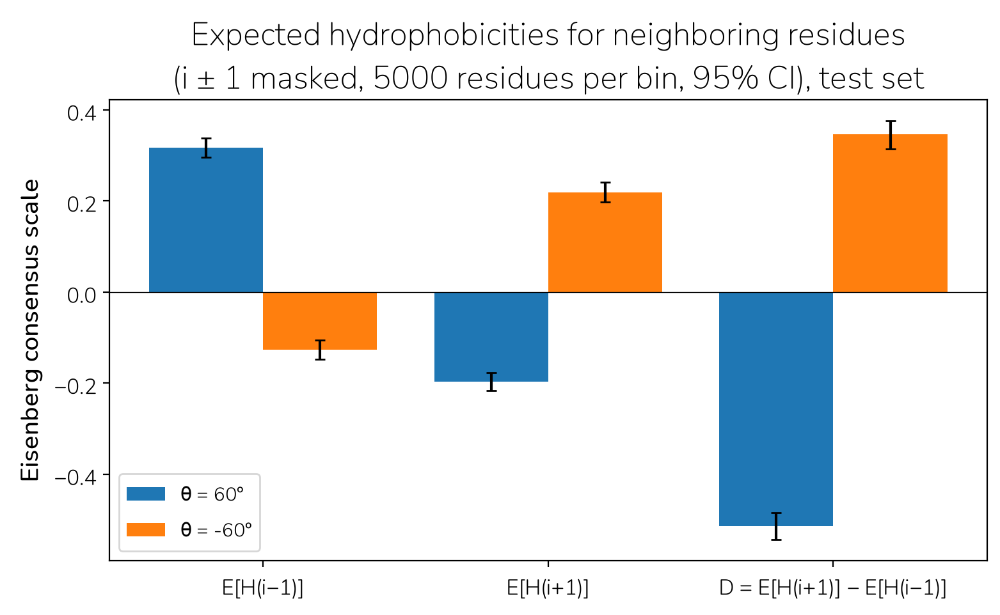

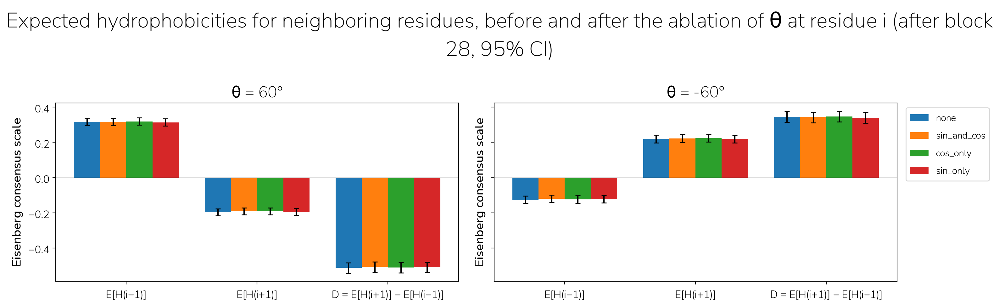

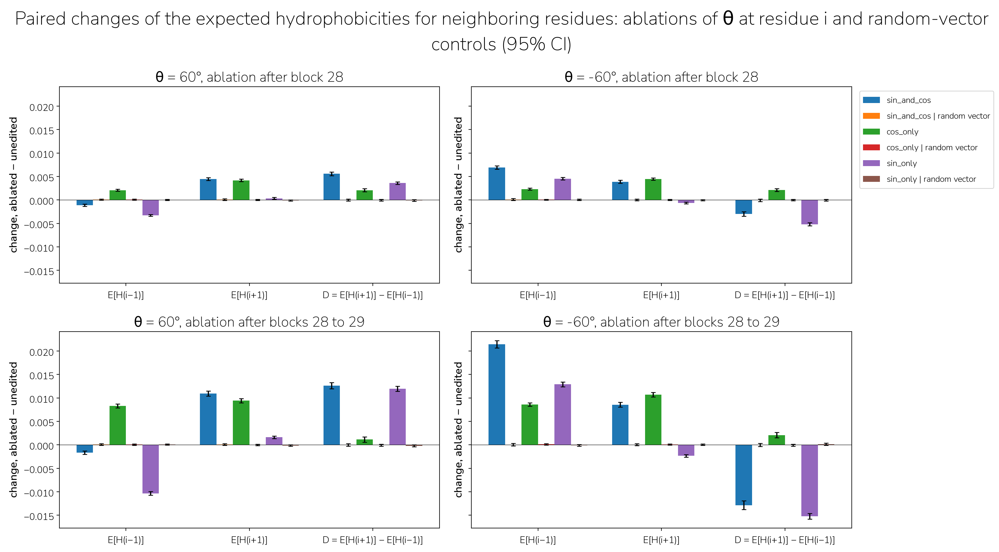

source_angle,condition,edit,metric,mean,low,high
i64,str,str,str,f64,f64,f64
-60,"""28""","""cos_only""","""D = E[H(i+1)] − E[H(i−1)]""",0.0021,0.0018,0.0024
-60,"""28""","""cos_only""","""E[H(i+1)]""",0.0044,0.0042,0.0047
-60,"""28""","""cos_only""","""E[H(i−1)]""",0.0023,0.0021,0.0025
-60,"""28""","""cos_only | random vector""","""D = E[H(i+1)] − E[H(i−1)]""",-0.0000,-0.0002,0.0001
-60,"""28""","""cos_only | random vector""","""E[H(i+1)]""",0.0000,-0.0001,0.0001
-60,"""28""","""cos_only | random vector""","""E[H(i−1)]""",0.0000,-0.0001,0.0002
-60,"""28""","""sin_and_cos""","""D = E[H(i+1)] − E[H(i−1)]""",-0.0030,-0.0035,-0.0025
-60,"""28""","""sin_and_cos""","""E[H(i+1)]""",0.0039,0.0036,0.0042
-60,"""28""","""sin_and_cos""","""E[H(i−1)]""",0.0069,0.0065,0.0073


In [5]:
METRICS = {"E[H(i−1)]": "eh_before", "E[H(i+1)]": "eh_after", "D = E[H(i+1)] − E[H(i−1)]": "D"}
N_BOOT = 2000


def summarise(results_dir, residues, keys):
    """Values, paired changes (edit - none, per residue) and changes in percent of the unedited mean, for each bin, group of `keys` and edit;
    95% CIs with the same bootstrap samples of the residues for every group, edit and metric of a bin."""
    scores = (pl.read_parquet(results_dir / "*.parquet").join(residues.select("n", "source_angle"), on="n")
              .with_columns(pl.col("edit").str.replace("harmonic", "sin_and_cos"), D=pl.col("eh_after") - pl.col("eh_before")).sort("n"))
    assert (scores.group_by(keys).agg(pl.col("n").n_unique())["n"] == len(residues)).all(), "some residues are missing"
    rows = []
    for (angle, *key), group in scores.group_by(["source_angle", *keys], maintain_order=True):
        none = group.filter(pl.col("edit") == "none")
        resample = np.random.default_rng(0).integers(0, len(none), (N_BOOT, len(none)))
        for edit in EDITS:
            d = group.filter(pl.col("edit") == edit)
            for metric, column in METRICS.items():
                a, b = d[column].to_numpy(), none[column].to_numpy()
                boot_a, boot_b = a[resample].mean(1), b[resample].mean(1)  # the same residues in both, so the change is paired
                for kind, mean, boot in [("value", a.mean(), boot_a), ("change", a.mean() - b.mean(), boot_a - boot_b),
                                         ("percent", 100 * (a.mean() / b.mean() - 1), 100 * (boot_a / boot_b - 1))]:
                    rows.append({"source_angle": angle, **dict(zip(keys, key)), "edit": edit, "kind": kind, "metric": metric, "mean": mean,
                                 **dict(zip(["low", "high"], np.percentile(boot, [2.5, 97.5])))})
    return pl.DataFrame(rows)


summary = summarise(NEIGHBOURS_DIR / "results", neighbour_residues, ["condition"])


def after(condition):
    return f"ablation after block{'s' if '-' in condition else ''} {condition.replace('-', ' to ')}"


def bars(ax, groups, labels, ylabel="Eisenberg consensus scale", data=summary):
    """For each metric, one bar per group (filters of `summary`) next to each other, with 95% CI whiskers."""
    width = 0.8 / len(groups)
    for k, (group, label) in enumerate(zip(groups, labels)):
        d = pl.DataFrame({"metric": list(METRICS)}).join(data.filter(group), on="metric", maintain_order="left")
        ax.bar(np.arange(len(METRICS)) + (k - (len(groups) - 1) / 2) * width, d["mean"], width, label=label, capsize=3,
               yerr=[d["mean"] - d["low"], d["high"] - d["mean"]])
    ax.set_xticks(range(len(METRICS)), list(METRICS))
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_ylabel(ylabel)


def paired_changes(panels, data=summary, residue="residue i"):
    """Paired changes, one row per panel (title: filter of `data`) and one column per bin: if an ablation removes the angle that the model reads,
    D moves toward 0 (up at 60°, down at -60°), and its control does not."""
    fig, axes = plt.subplots(len(panels), len(ANGLES), figsize=(18, 5 * len(panels)), sharey=True, squeeze=False)
    for row, (title, panel) in zip(axes, panels.items()):
        for ax, angle in zip(row, ANGLES):
            bars(ax, [panel & (pl.col("kind") == "change") & (pl.col("edit") == e) & (pl.col("source_angle") == angle) for e in EDITS[1:]], EDITS[1:],
                 "change, ablated − unedited", data)
            ax.set_title(f"θ = {angle}°, {title}")
    axes[0, -1].legend(fontsize="small", loc="upper left", bbox_to_anchor=(1.01, 1))  # outside, to the right
    fig.suptitle(f"Paired changes of the expected hydrophobicities for neighboring residues: ablations of θ at {residue} and random-vector controls (95% CI)")
    plt.tight_layout()
    plt.show()
    with pl.Config(tbl_rows=-1, float_precision=4):
        display(data.filter(pl.any_horizontal(list(panels.values())), pl.col("kind") == "change", pl.col("edit") != "none")
                .sort([c for c in data.columns if c not in ["kind", "mean", "low", "high"]]).drop("kind"))


fig, ax = plt.subplots(figsize=(8, 5))
bars(ax, [(pl.col("kind") == "value") & (pl.col("condition") == "28") & (pl.col("edit") == "none") & (pl.col("source_angle") == a) for a in ANGLES],
     [f"θ = {a}°" for a in ANGLES])
ax.legend(fontsize="small")
ax.set_title(f"Expected hydrophobicities for neighboring residues\n(i ± 1 masked, {N_NEIGHBOURS} residues per bin, 95% CI), test set", wrap=False)
plt.tight_layout()
plt.show()

ABLATIONS = [e for e in EDITS if "random" not in e]  # with "none"
fig, axes = plt.subplots(1, len(ANGLES), figsize=(16, 5), sharey=True)
for ax, angle in zip(axes, ANGLES):
    bars(ax, [(pl.col("kind") == "value") & (pl.col("condition") == "28") & (pl.col("edit") == e) & (pl.col("source_angle") == angle) for e in ABLATIONS], ABLATIONS)
    ax.set_title(f"θ = {angle}°")
axes[-1].legend(fontsize="small", loc="upper left", bbox_to_anchor=(1.01, 1))  # outside, to the right
fig.suptitle("Expected hydrophobicities for neighboring residues, before and after the ablation of θ at residue i (after block 28, 95% CI)")
plt.tight_layout()
plt.show()
paired_changes({after(c): pl.col("condition") == c for c in ["28", "28-29"]})

### Results: ablation from layers 22, 20, 18 and 16
The same paired changes, with the ablation after one block only, and after each block from there to 29. The later blocks can carry the edit of residue $i$ to $i \pm 1$; with the ablation after each block, they cannot compute the angle of $i$ again.

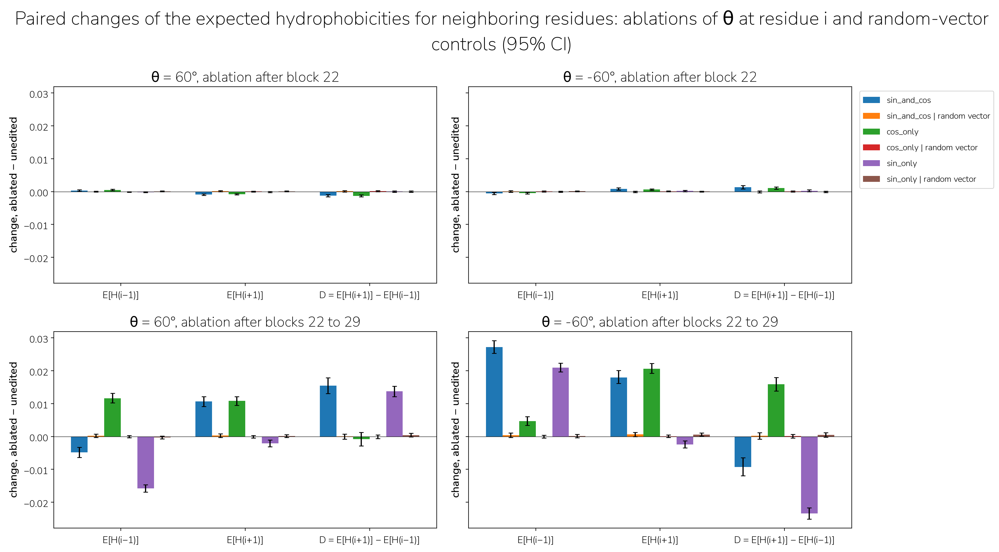

source_angle,condition,edit,metric,mean,low,high
i64,str,str,str,f64,f64,f64
-60,"""22""","""cos_only""","""D = E[H(i+1)] − E[H(i−1)]""",0.0011,0.0007,0.0014
-60,"""22""","""cos_only""","""E[H(i+1)]""",0.0006,0.0004,0.0008
-60,"""22""","""cos_only""","""E[H(i−1)]""",-0.0005,-0.0007,-0.0002
-60,"""22""","""cos_only | random vector""","""D = E[H(i+1)] − E[H(i−1)]""",0.0000,-0.0002,0.0002
-60,"""22""","""cos_only | random vector""","""E[H(i+1)]""",0.0001,-0.0000,0.0002
-60,"""22""","""cos_only | random vector""","""E[H(i−1)]""",0.0000,-0.0001,0.0002
-60,"""22""","""sin_and_cos""","""D = E[H(i+1)] − E[H(i−1)]""",0.0013,0.0008,0.0018
-60,"""22""","""sin_and_cos""","""E[H(i+1)]""",0.0008,0.0004,0.0011
-60,"""22""","""sin_and_cos""","""E[H(i−1)]""",-0.0005,-0.0009,-0.0002


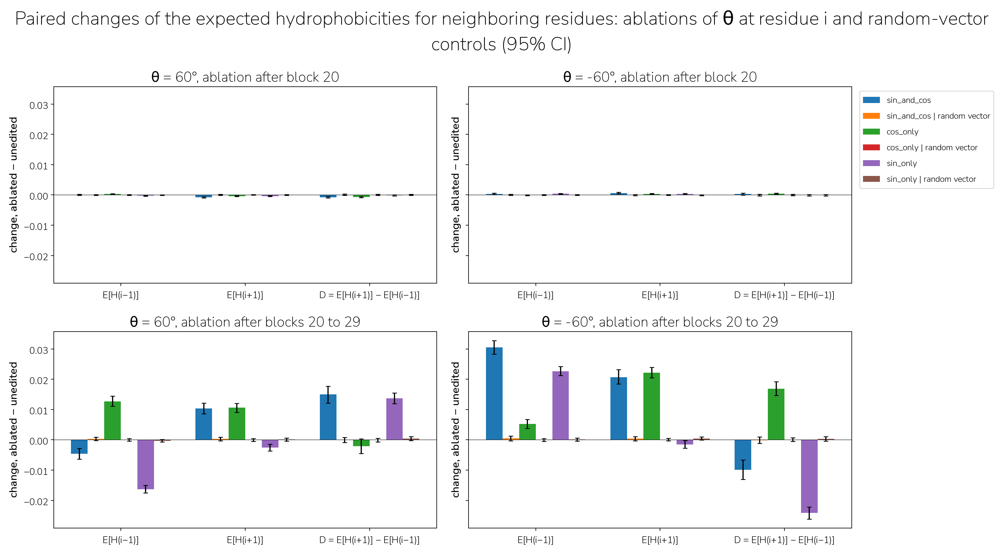

source_angle,condition,edit,metric,mean,low,high
i64,str,str,str,f64,f64,f64
-60,"""20""","""cos_only""","""D = E[H(i+1)] − E[H(i−1)]""",0.0004,0.0002,0.0006
-60,"""20""","""cos_only""","""E[H(i+1)]""",0.0004,0.0002,0.0005
-60,"""20""","""cos_only""","""E[H(i−1)]""",-0.0001,-0.0002,0.0001
-60,"""20""","""cos_only | random vector""","""D = E[H(i+1)] − E[H(i−1)]""",-0.0000,-0.0002,0.0002
-60,"""20""","""cos_only | random vector""","""E[H(i+1)]""",0.0000,-0.0001,0.0001
-60,"""20""","""cos_only | random vector""","""E[H(i−1)]""",0.0000,-0.0001,0.0001
-60,"""20""","""sin_and_cos""","""D = E[H(i+1)] − E[H(i−1)]""",0.0003,-0.0000,0.0006
-60,"""20""","""sin_and_cos""","""E[H(i+1)]""",0.0006,0.0004,0.0009
-60,"""20""","""sin_and_cos""","""E[H(i−1)]""",0.0004,0.0001,0.0006


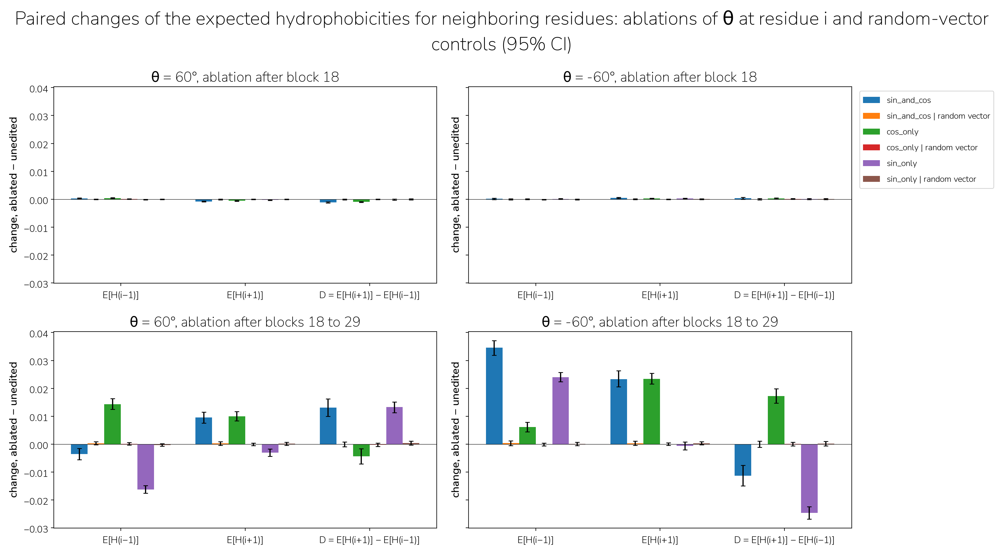

source_angle,condition,edit,metric,mean,low,high
i64,str,str,str,f64,f64,f64
-60,"""18""","""cos_only""","""D = E[H(i+1)] − E[H(i−1)]""",0.0003,0.0001,0.0005
-60,"""18""","""cos_only""","""E[H(i+1)]""",0.0003,0.0001,0.0004
-60,"""18""","""cos_only""","""E[H(i−1)]""",0.0000,-0.0001,0.0002
-60,"""18""","""cos_only | random vector""","""D = E[H(i+1)] − E[H(i−1)]""",0.0001,-0.0000,0.0003
-60,"""18""","""cos_only | random vector""","""E[H(i+1)]""",0.0000,-0.0001,0.0001
-60,"""18""","""cos_only | random vector""","""E[H(i−1)]""",-0.0001,-0.0002,0.0000
-60,"""18""","""sin_and_cos""","""D = E[H(i+1)] − E[H(i−1)]""",0.0004,0.0000,0.0007
-60,"""18""","""sin_and_cos""","""E[H(i+1)]""",0.0005,0.0003,0.0007
-60,"""18""","""sin_and_cos""","""E[H(i−1)]""",0.0001,-0.0001,0.0004


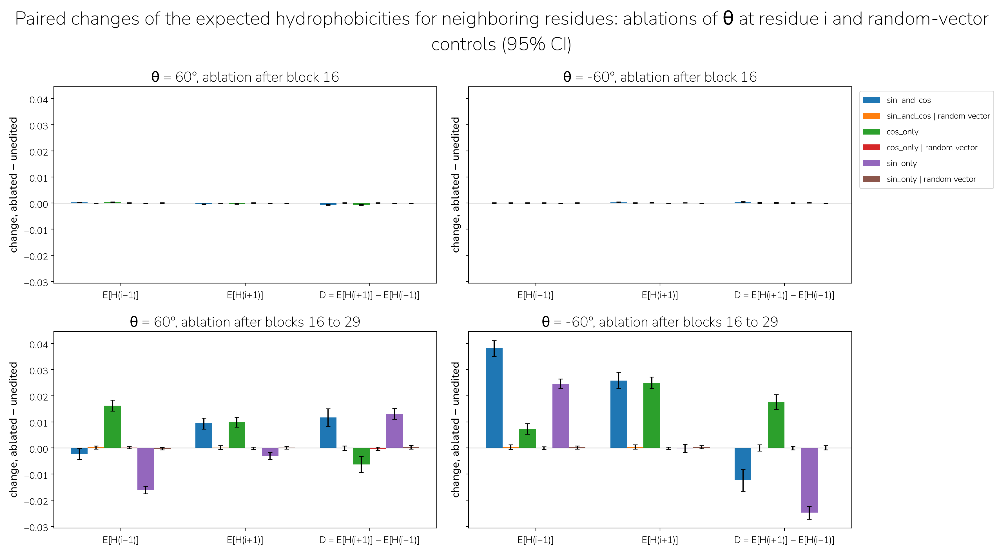

source_angle,condition,edit,metric,mean,low,high
i64,str,str,str,f64,f64,f64
-60,"""16""","""cos_only""","""D = E[H(i+1)] − E[H(i−1)]""",0.0001,-0.0000,0.0003
-60,"""16""","""cos_only""","""E[H(i+1)]""",0.0002,0.0001,0.0003
-60,"""16""","""cos_only""","""E[H(i−1)]""",0.0000,-0.0001,0.0001
-60,"""16""","""cos_only | random vector""","""D = E[H(i+1)] − E[H(i−1)]""",-0.0000,-0.0002,0.0001
-60,"""16""","""cos_only | random vector""","""E[H(i+1)]""",-0.0000,-0.0001,0.0001
-60,"""16""","""cos_only | random vector""","""E[H(i−1)]""",0.0000,-0.0001,0.0001
-60,"""16""","""sin_and_cos""","""D = E[H(i+1)] − E[H(i−1)]""",0.0003,0.0001,0.0006
-60,"""16""","""sin_and_cos""","""E[H(i+1)]""",0.0003,0.0001,0.0004
-60,"""16""","""sin_and_cos""","""E[H(i−1)]""",-0.0001,-0.0002,0.0001


In [6]:
for start in [22, 20, 18, 16]:
    paired_changes({after(c): pl.col("condition") == c for c in [f"{start}", f"{start}-29"]})

## Ablation at all the residues from $i - n$ to $i + n$
With $i \pm 1$ masked, the model can read the angle of the helix at more than one residue: an ablation at $i$ only is not sufficient if it reads the angle again from the other residues of the helix. Here we ablate a window of residues around $i$, and make it larger.
- Residues: a new sample of the same 2 bins, 5000 residues per bin, one residue per protein, only residues with helix residues from $i-5$ to $i+5$ in the same helix (helices of 11 residues or more). A first run with windows up to $i \pm 8$ (helices of 17 residues or more) gave $D$ near 0 at -60° (+0.02): in long helices the mean $D$ of a bin is not the same, and a percentage of a value near 0 has no stable value. With $i \pm 5$, $D$ is far from 0 in the 2 bins. The results at residue $i$ are thus not the same as above.
- Sites of the ablation, on the same residues: for $n = 1, \dots, 5$, all the residues from $i-n$ to $i+n$ except the masked neighbours $i \pm 1$ ($n = 1$: residue $i$ only; $n = 2$: $i$, $i \pm 2$; ...). Each residue with its own angle and the fits as above ($h \leftarrow h - \hat h(\theta) + \mu$).
- Conditions: the ablation after block 28 only, after blocks 28 and 29, after block 22 only, and after each block from 22 to 29. Random-vector controls as above, with a different direction for each residue (`default_rng([0, n, offset + 5, k, L])`): the ablation and the control of a residue are the same for all the sites that contain it.

Cell tagged `local`: the inputs. Cell tagged `sites`: the passes (the shared cell above, with the encoders of the `encoders` cell; `scripts/runpod_notebook.sh` with the tag `sites`).


In [7]:
N_MAX = 5  # the largest window: residues i - 5 to i + 5
SITES = {n: [offset for offset in range(-n, n + 1) if abs(offset) != 1] for n in range(1, N_MAX + 1)}  # offsets of the ablated residues from residue i, not the masked neighbours
SITES_DIR = NEIGHBOURS_DIR / "sites"
(SITES_DIR / "inputs").mkdir(parents=True, exist_ok=True)

site_residues = sample_residues(N_MAX)
# the angle of each residue from i - N_MAX to i + N_MAX (the same helix)
faces = (site_residues.select("n", "accession", "i").join(pl.DataFrame({"offset": range(-N_MAX, N_MAX + 1)}), how="cross").with_columns(j=pl.col("i") + pl.col("offset")).lazy()
         .join(labels.select("accession", j="i", face="helix_face"), on=["accession", "j"]).sort("n", "offset").group_by("n", maintain_order=True)
         .agg(faces="face").collect(engine="streaming"))
site_residues = site_residues.join(faces, on="n", maintain_order="left")
assert len(site_residues) == len(ANGLES) * N_NEIGHBOURS and (site_residues["faces"].list.len() == 2 * N_MAX + 1).all() and site_residues["faces"].list.eval(pl.element().is_null().any()).explode().not_().all()
site_residues.write_parquet(SITES_DIR / "inputs" / "residues.parquet")
site_residues.select("n", "source_angle", "i", "helix_face", "faces").head()


2,892,715 helix residues with 5 helix residue(s) on each side


n,source_angle,i,helix_face,faces
u32,i32,i32,f32,list[f32]
0,60,177,57.933475,"[-107.605812, 43.778652, … 171.36821]"
1,60,64,59.253983,"[-59.321781, 33.112122, … 175.815781]"
2,60,236,58.468018,"[-67.315773, 14.066059, … -136.901611]"
3,60,337,57.748058,"[-113.385208, -39.073761, … -144.47818]"
4,60,92,58.179848,"[-112.345825, 47.848484, … -155.128479]"


In [ ]:
N_MAX = 5  # the largest window: residues i - 5 to i + 5
SITES = {n: [offset for offset in range(-n, n + 1) if abs(offset) != 1] for n in range(1, N_MAX + 1)}  # offsets of the ablated residues from residue i, not the masked neighbours
SITE_CONDITIONS = {"28": [28], "28-29": [28, 29], "22": [22], "22-29": list(range(22, 30))}  # the ablation after each of these blocks
SITES_DIR = NEIGHBOURS_DIR / "sites"
(SITES_DIR / "results").mkdir(exist_ok=True)
done = set(pl.read_parquet(SITES_DIR / "results" / "*.parquet", columns=["condition"])["condition"]) if any((SITES_DIR / "results").iterdir()) else set()
SITE_CONDITIONS = {c: layers for c, layers in SITE_CONDITIONS.items() if c not in done}  # the conditions without results
path = SITES_DIR / "results" / f"{'_'.join(SITE_CONDITIONS)}_shard_{SHARD}_of_{N_SHARDS}.parquet"

frames = []
for n, i, faces, sequence in tqdm(pl.read_parquet(SITES_DIR / "inputs" / "residues.parquet").filter(pl.col("n") % N_SHARDS == SHARD)
                                  .select("n", "i", "faces", "sequence").iter_rows(), desc=f"shard {SHARD}", mininterval=30):
    input_ids, _ = model.token_ids([sequence])
    position = i + model.offset
    input_ids[0, [position - 1, position + 1]] = model.mask_id  # the neighbours are masked, residue i is not
    h, previous, start = model.embed(input_ids), 0, {}
    for layer in sorted({layers[0] for layers in SITE_CONDITIONS.values()}):  # the unedited stream at the first layer of each condition
        h = start[layer] = model.run(h, previous, layer)
        previous = layer
    for site, offsets in SITES.items():
        for condition, layers in SITE_CONDITIONS.items():
            h = start[layers[0]].repeat(len(EDITS), 1, 1)  # one copy per edit
            for layer, end in zip(layers, layers[1:] + [model.n_layers]):
                for offset in offsets:
                    h[:, position + offset] += deltas([n, offset + N_MAX], faces[offset + N_MAX], layer)
                h = model.run(h, layer, end)
            frames.append(neighbour_scores(h, position, n=n, site=site, condition=condition))
pl.concat(frames).write_parquet(path.with_suffix(".tmp"))
path.with_suffix(".tmp").rename(path)  # a results file exists only when it is complete


### Results: ablation of the window from $i - n$ to $i + n$
For each condition, 2 figures with the same layout; controls dashed. The y axis is upside down where needed, so that down is always toward the other bin.
- The values after the ablation (unedited values in black), with the CIs of each value (bootstrap of the residues). If the window contains the residues where the model reads the angle, each metric is the same in the 2 bins.
- The changes in percent of the unedited value: $100\,(\bar{x}_{\text{ablated}} / \bar{x}_{\text{unedited}} - 1)$, with the CIs of the change (the same bootstrap samples of the residues for both means). The same residues with and without the ablation, so the variation between residues, the same in both, is not part of the comparison: these CIs tell if an ablation has an effect; the CIs of the values do not. Where the unedited mean is near 0 ($E[H(i-1)]$ at -60°: -0.05), the percentages are large and their CIs wide.


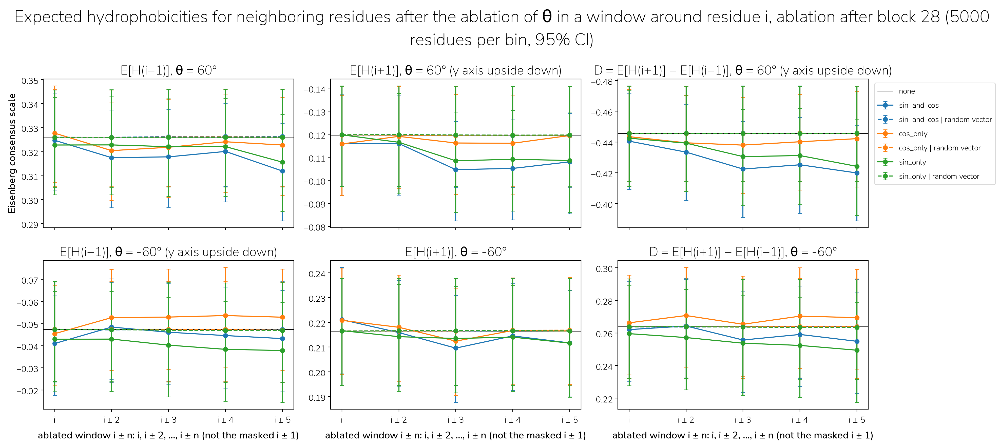

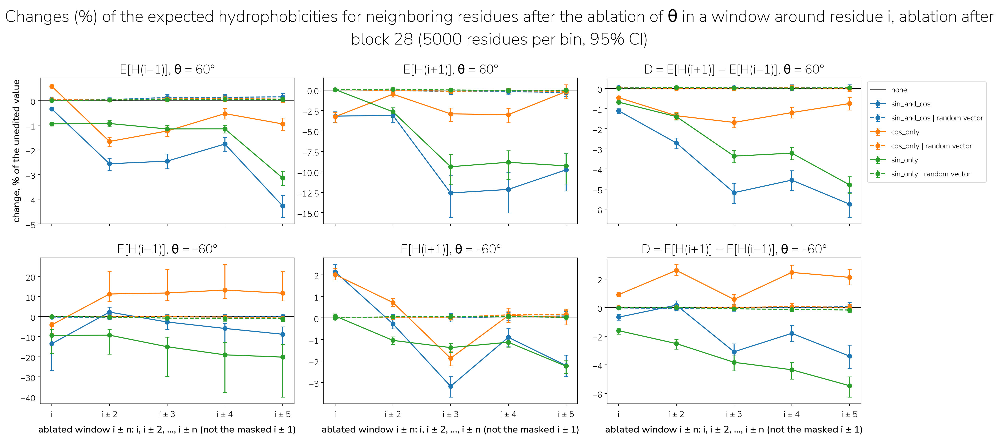

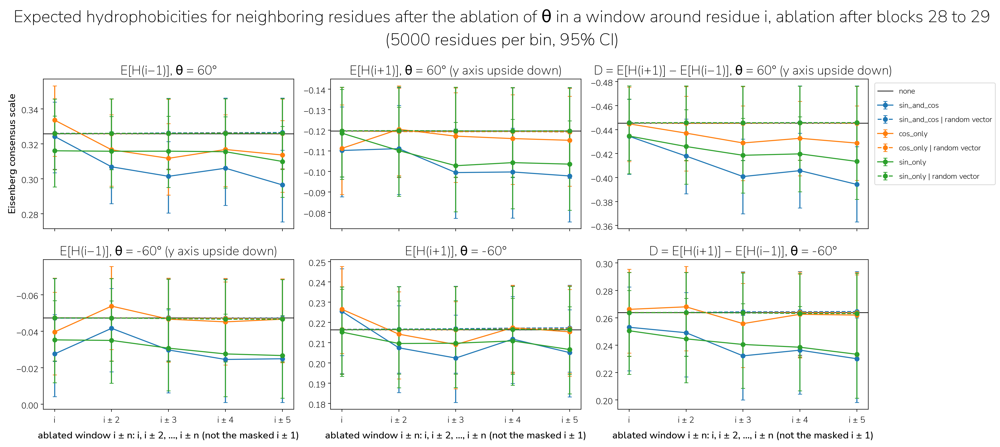

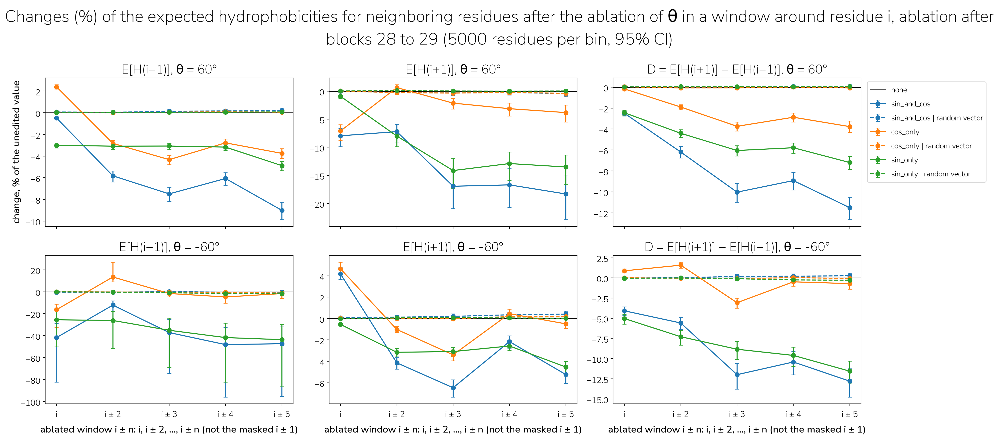

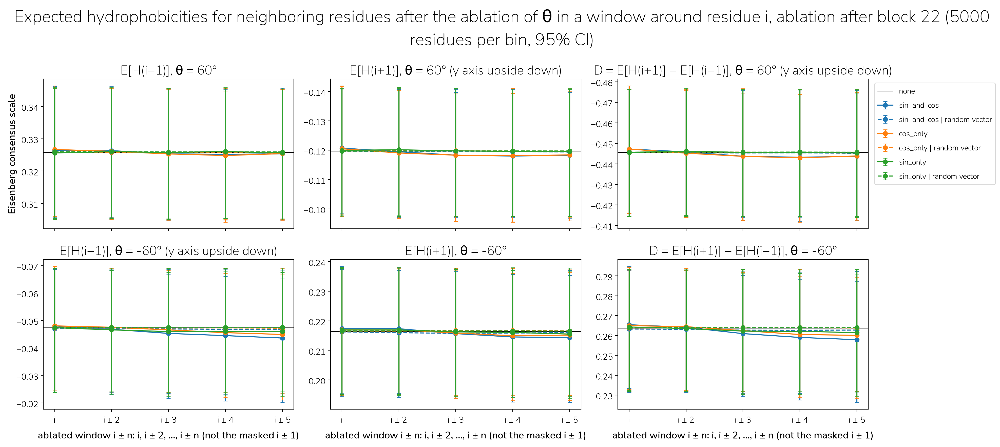

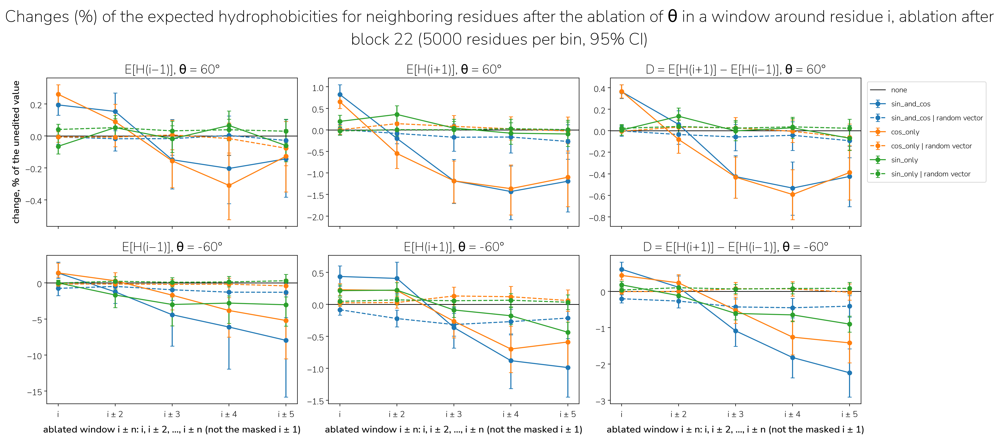

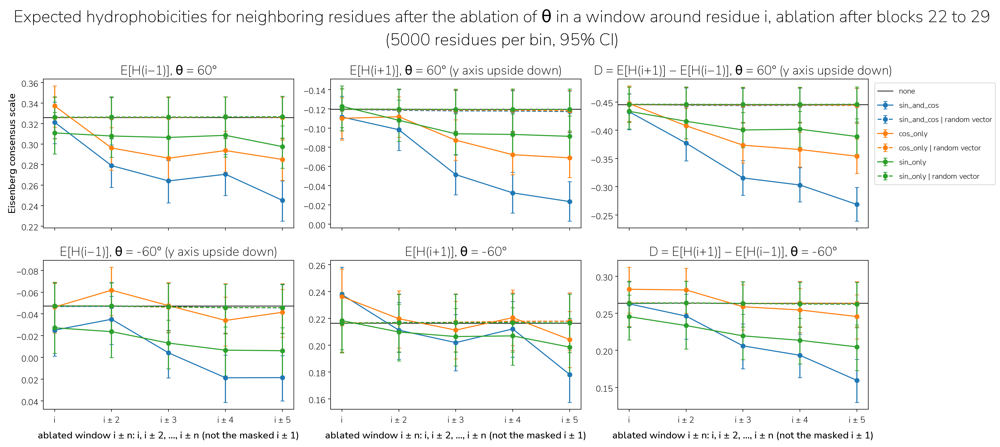

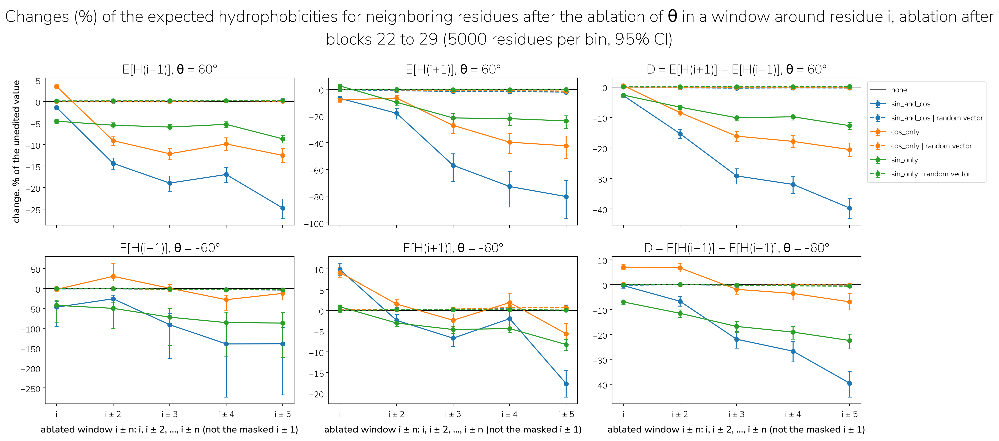

condition,source_angle,site,none,sin_and_cos,cos_only,sin_only
str,i64,i64,f64,f64,f64,f64
"""22""",-60,1,0.2638,0.2654,0.2650,0.2643
"""22""",-60,2,0.2638,0.2641,0.2644,0.2635
"""22""",-60,3,0.2638,0.2610,0.2625,0.2622
"""22""",-60,4,0.2638,0.2590,0.2605,0.2621
"""22""",-60,5,0.2638,0.2579,0.2601,0.2614
"""22""",60,1,-0.4455,-0.4471,-0.4472,-0.4456
"""22""",60,2,-0.4455,-0.4458,-0.4452,-0.4461
"""22""",60,3,-0.4455,-0.4436,-0.4436,-0.4455
"""22""",60,4,-0.4455,-0.4432,-0.4429,-0.4457


In [8]:
site_summary = summarise(SITES_DIR / "results", site_residues, ["site", "condition"])


def window_figure(condition, kind, data, sites):
    """The values or the changes in percent of each metric (columns) and bin (rows) against the window, for the summary `data` of a run with the windows `sites`."""
    fig, axes = plt.subplots(len(ANGLES), len(METRICS), figsize=(20, 9), sharex=True)
    for col, metric in zip(axes.T, METRICS):
        v = data.filter(pl.col("condition") == condition, pl.col("metric") == metric)
        unedited = dict(v.filter(pl.col("kind") == "value", pl.col("edit") == "none", pl.col("site") == 1).select("source_angle", "mean").iter_rows())
        for ax, angle in zip(col, ANGLES):
            for k, edit in enumerate(EDITS[1:]):  # each ablation (solid) and its control (dashed) in the same colour
                d = v.filter(pl.col("kind") == kind, pl.col("source_angle") == angle, pl.col("edit") == edit).sort("site")
                ax.errorbar(d["site"], d["mean"], [d["mean"] - d["low"], d["high"] - d["mean"]], color=f"C{k // 2}", linestyle="--" if k % 2 else "-",
                            marker="o", capsize=3, label=edit)
            ax.axhline(unedited[angle] if kind == "value" else 0, color="black", linewidth=1, label="none")
            toward = sum(unedited.values()) - 2 * unedited[angle]  # the sign of the direction toward the other bin
            if (toward / unedited[angle] if kind == "percent" else toward) > 0:
                ax.invert_yaxis()  # down: toward the other bin
            ax.set_title(f"{metric}, θ = {angle}°{' (y axis upside down)' if ax.yaxis_inverted() else ''}")
            ax.set_xticks(list(sites), ["i"] + [f"i ± {n}" for n in list(sites)[1:]])
    for ax in axes[-1]:
        ax.set_xlabel("ablated window i ± n: i, i ± 2, ..., i ± n (not the masked i ± 1)")
    axes[0, 0].set_ylabel("Eisenberg consensus scale" if kind == "value" else "change, % of the unedited value")
    axes[0, -1].legend(fontsize="small", loc="upper left", bbox_to_anchor=(1.01, 1))  # outside, to the right
    fig.suptitle(f"{'Expected hydrophobicities' if kind == 'value' else 'Changes (%) of the expected hydrophobicities'} for neighboring residues after the ablation "
                 f"of θ in a window around residue i, {after(condition)} ({N_NEIGHBOURS} residues per bin, 95% CI{' of the change' if kind == 'change' else ''})")
    plt.tight_layout()
    plt.show()


def d_table(data):
    """The mean D of each bin, condition and window after each ablation."""
    with pl.Config(tbl_rows=-1, float_precision=4):
        display(data.filter(pl.col("kind") == "value", pl.col("metric").str.starts_with("D"), ~pl.col("edit").str.contains("random"))
                .pivot(on="edit", index=["condition", "source_angle", "site"], values="mean").sort("condition", "source_angle", "site"))


for condition in ["28", "28-29", "22", "22-29"]:
    for kind in ["value", "percent"]:
        window_figure(condition, kind, site_summary, SITES)
d_table(site_summary)


### Wider windows: up to $i \pm 8$
The first run of this experiment: the same passes with `N_MAX = 8` in the 2 cells above (results in `sites_n8`), on residues with helix residues from $i-8$ to $i+8$ (helices of 17 residues or more: the longest 25% of the helices of the test set, 13% of the helix residues). After the harmonic ablation after each block from 22 to 29, $D$ of the 2 bins is almost the same from $i \pm 6$ or $i \pm 7$: almost all of the angle signal that the masked neighbours use is in these windows.

Caveat: this sample is not the sample above. In these long helices, the unedited $D$ is smaller, and near 0 at -60° (+0.02), so the changes in percent have no stable value (the reason for the run with $i \pm 5$ above); only the values are shown here.

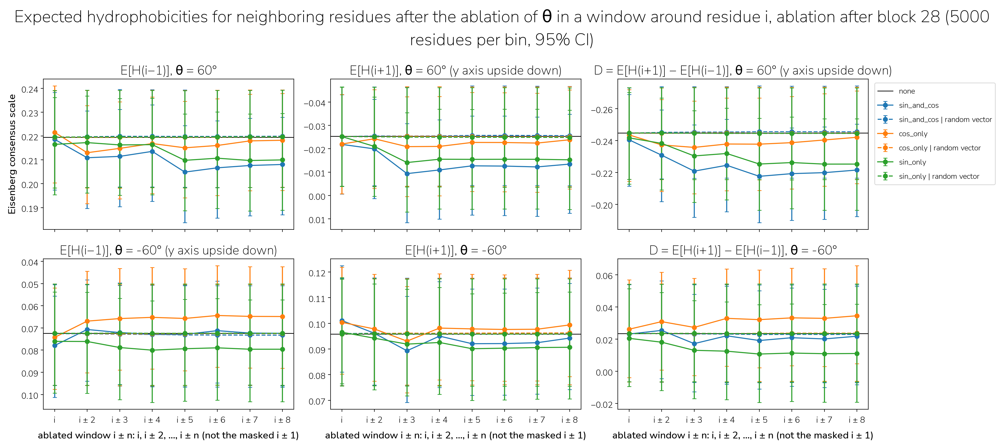

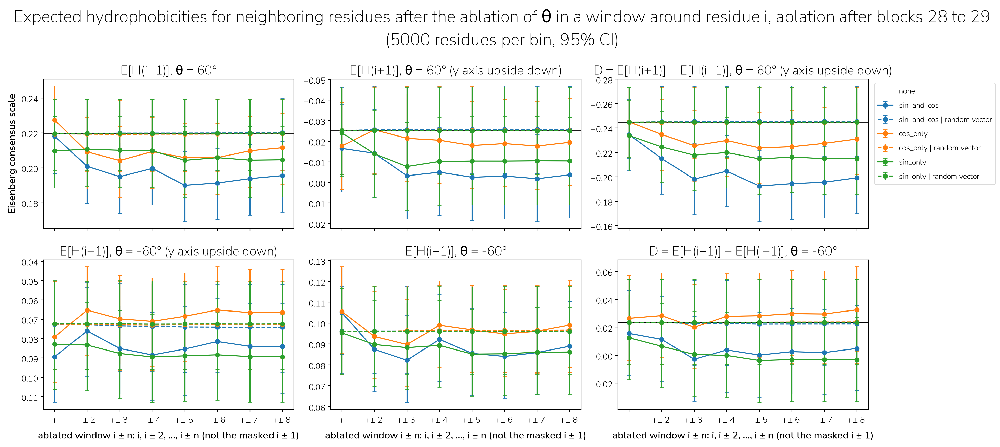

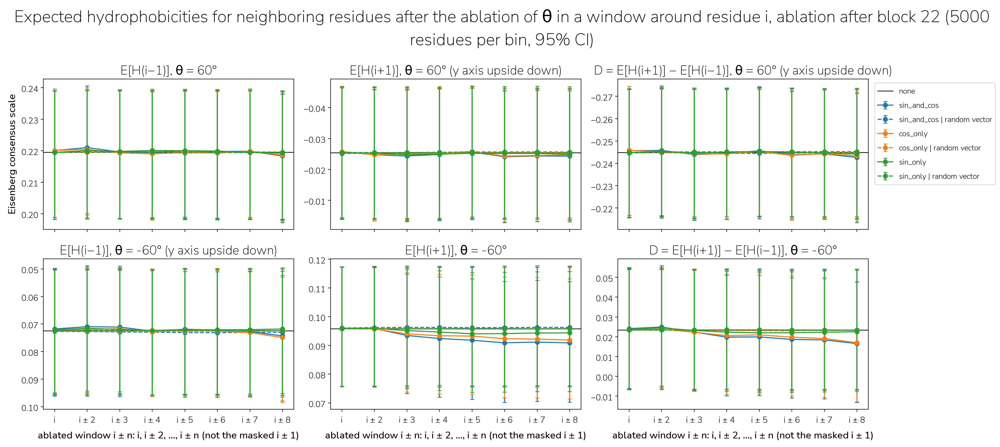

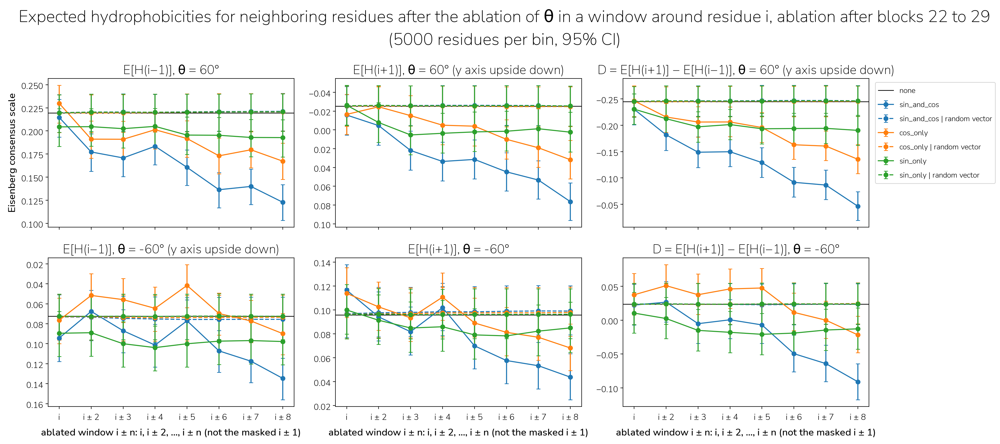

condition,source_angle,site,none,sin_and_cos,cos_only,sin_only
str,i64,i64,f64,f64,f64,f64
"""22""",-60,1,0.0234,0.0241,0.0237,0.0239
"""22""",-60,2,0.0234,0.0249,0.0238,0.0244
"""22""",-60,3,0.0234,0.0223,0.0223,0.0232
"""22""",-60,4,0.0234,0.0198,0.0206,0.0223
"""22""",-60,5,0.0234,0.0199,0.0210,0.0220
"""22""",-60,6,0.0234,0.0186,0.0198,0.0220
"""22""",-60,7,0.0234,0.0184,0.0191,0.0223
"""22""",-60,8,0.0234,0.0166,0.0170,0.0226
"""22""",60,1,-0.2449,-0.2457,-0.2459,-0.2448


In [9]:
WIDE_DIR = NEIGHBOURS_DIR / "sites_n8"
wide_summary = summarise(WIDE_DIR / "results", pl.read_parquet(WIDE_DIR / "inputs" / "residues.parquet"), ["site", "condition"])
for condition in ["28", "28-29", "22", "22-29"]:
    window_figure(condition, "value", wide_summary, range(1, 9))
d_table(wide_summary)


## Steering the angle of residue $i$
As in notebook 5, but with the neighbours $i \pm 1$ masked and residue $i$ not masked: steer from the angle of the residue to each target angle with the harmonic fit of each layer, $h \leftarrow h - \hat h(\theta) + \hat h(\theta_{target})$, and read $E[H(i-1)]$, $E[H(i+1)]$ and $D$ at the masked neighbours.
- Residues: the sample of the windows above (the 2 bins, 5000 residues per bin, helix residues from $i-5$ to $i+5$).
- Targets: 72 angles, every 5 degrees. Controls: random vectors with the norm of the steering edit to source + 45, 90, 180 and -90 degrees (`default_rng([1, n, offset + 5, L])`: one direction per control, residue and layer).
- Sites: residue $i$ only, and the window from $i-5$ to $i+5$ without the masked $i \pm 1$. In the window, each residue turns by the same angle as residue $i$ ($\theta_{target} - \theta_i$), from its own angle: the helix turns as a whole.
- Conditions: the edit after block 22 only, after each block from 22 to 29, after block 28 only, and after blocks 28 and 29.
- 95% CIs from the standard error (one residue per protein).

Cell tagged `steer`: the passes (the shared cell above; `scripts/runpod_notebook.sh` with the tag `steer`).

In [ ]:
N_MAX = 5  # the window: residues i - 5 to i + 5
TARGETS = np.arange(-180, 180, 5)  # target angles of residue i, degrees
CONTROL_OFFSETS = [45, 90, 180, -90]  # random-vector controls, with the norm of the steering edit to source + offset
STEER_EDITS = ["none"] + [f"target {t}" for t in TARGETS] + [f"random vector {o}" for o in CONTROL_OFFSETS]
STEER_SITES = {"i": [0], f"i ± {N_MAX}": [offset for offset in range(-N_MAX, N_MAX + 1) if abs(offset) != 1]}  # offsets of the steered residues, not the masked neighbours
STEER_CONDITIONS = {"22": [22], "22-29": list(range(22, 30)), "28": [28], "28-29": [28, 29]}  # the edit after each of these blocks
STEER_DIR = NEIGHBOURS_DIR / "steer"
(STEER_DIR / "results").mkdir(parents=True, exist_ok=True)
path = STEER_DIR / "results" / f"shard_{SHARD}_of_{N_SHARDS}.parquet"


def steer_deltas(seed, face, turns, layer):
    """The changes of the stream of a residue after a block, in the order of STEER_EDITS: h <- h - h_pred(face) + h_pred(face + turn), and the random vectors."""
    h_pred = lambda angle: linear_fits.predict(fits[layer]["harmonic"], VARIABLES["harmonic"](np.deg2rad(angle)))
    directions = np.random.default_rng([1, *seed, layer]).standard_normal((len(CONTROL_OFFSETS), model.hidden_size))
    norms = np.linalg.norm(h_pred(face + np.array(CONTROL_OFFSETS)) - h_pred(face), axis=1, keepdims=True)
    out = np.concatenate([np.zeros((1, model.hidden_size)), h_pred(face + turns) - h_pred(face), directions / np.linalg.norm(directions, axis=1, keepdims=True) * norms])
    return torch.tensor(out, dtype=torch.float32, device=model.device)


frames = []
for n, i, faces, sequence in tqdm(pl.read_parquet(NEIGHBOURS_DIR / "sites" / "inputs" / "residues.parquet").filter(pl.col("n") % N_SHARDS == SHARD)
                                  .select("n", "i", "faces", "sequence").iter_rows(), desc=f"shard {SHARD}", mininterval=30):
    input_ids, _ = model.token_ids([sequence])
    position = i + model.offset
    input_ids[0, [position - 1, position + 1]] = model.mask_id  # the neighbours are masked, residue i is not
    h, previous, start = model.embed(input_ids), 0, {}
    for layer in sorted({layers[0] for layers in STEER_CONDITIONS.values()}):  # the unedited stream at the first layer of each condition
        h = start[layer] = model.run(h, previous, layer)
        previous = layer
    turns = TARGETS - faces[N_MAX]  # each residue turns by the same angle as residue i
    delta = {(offset, layer): steer_deltas([n, offset + N_MAX], faces[offset + N_MAX], turns, layer)
             for offset in STEER_SITES[f"i ± {N_MAX}"] for layer in range(22, 30)}
    for site, offsets in STEER_SITES.items():
        for condition, layers in STEER_CONDITIONS.items():
            h = start[layers[0]].repeat(len(STEER_EDITS), 1, 1)  # one copy per edit
            for layer, end in zip(layers, layers[1:] + [model.n_layers]):
                for offset in offsets:
                    h[:, position + offset] += delta[offset, layer]
                h = model.run(h, layer, end)
            frames.append(neighbour_scores(h, position, STEER_EDITS, n=n, site=site, condition=condition).drop("aa_log_probs_before", "aa_log_probs_after"))
pl.concat(frames).write_parquet(path.with_suffix(".tmp"))
path.with_suffix(".tmp").rename(path)  # a results file exists only when it is complete


### Results: steering
One figure per condition: the mean of each metric against the target angle of residue $i$, one colour per source bin; solid: steering at residue $i$ only, dashed: steering of the window. The dot is the unedited value at the source angle; the crosses are the random-vector controls (at source + offset). If the model reads the angle from the steered residues, each curve goes from the unedited value of its bin to the unedited value of the other bin at the angle of the other bin.

Then the same means on wheels, as in notebook 5: one figure per condition, one wheel per source bin (rows) and metric (columns). Each wheel is a ring of 5-degree target sectors, coloured by the mean of the metric after steering of the window to that target (steering at residue $i$ only has almost no effect: not shown). The dot is at the source angle. The colour scales are the same in all the figures.

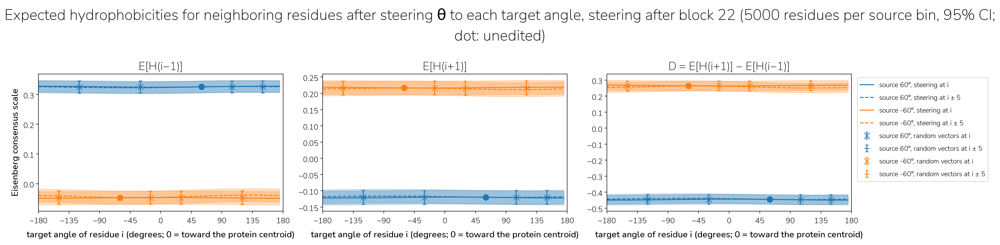

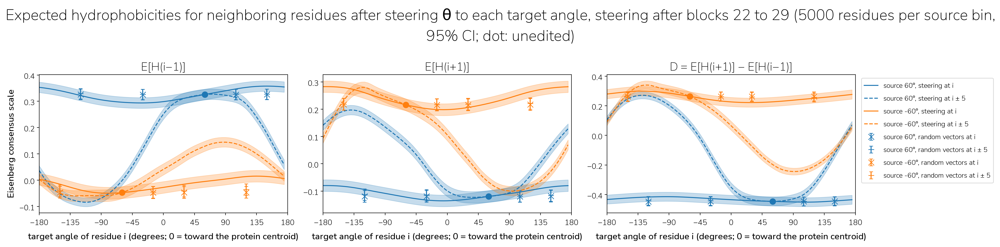

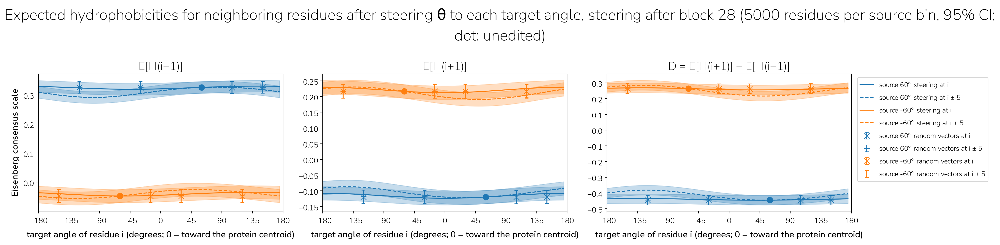

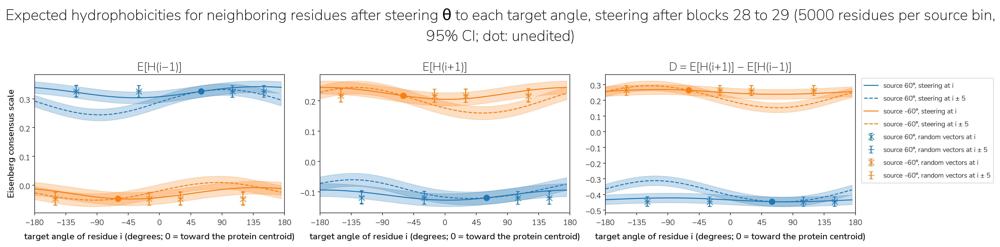

In [10]:
STEER_DIR = NEIGHBOURS_DIR / "steer"
steer = (pl.read_parquet(STEER_DIR / "results" / "*.parquet").join(site_residues.select("n", "source_angle"), on="n")
         .with_columns(D=pl.col("eh_after") - pl.col("eh_before")))
assert (steer.group_by("site", "condition").agg(pl.col("n").n_unique())["n"] == len(site_residues)).all(), "some residues are missing"
steer_summary = (
    steer.group_by("source_angle", "site", "condition", "edit")
    .agg(*[pl.col(c).mean() for c in METRICS.values()], *[(1.96 * pl.col(c).std() / pl.len().sqrt()).alias(f"ci_{c}") for c in METRICS.values()])
    .with_columns(angle=pl.col("edit").str.extract(r"(-?\d+)$").cast(pl.Int64))  # the target, or the offset of a control
    .with_columns(x=pl.when(pl.col("edit").str.starts_with("random")).then((pl.col("source_angle") + pl.col("angle") + 180) % 360 - 180).otherwise("angle"))
)


def steering_figure(condition):
    """The mean of each metric against the target angle, for each source bin and site."""
    fig, axes = plt.subplots(1, len(METRICS), figsize=(22, 5.5))
    for ax, (metric, column) in zip(axes, METRICS.items()):
        for k, source in enumerate(ANGLES):
            for site, style, marker in zip(["i", f"i ± {N_MAX}"], ["-", "--"], ["x", "+"]):
                d = steer_summary.filter(pl.col("condition") == condition, pl.col("source_angle") == source, pl.col("site") == site)
                s = d.filter(pl.col("edit").str.starts_with("target")).sort("x")
                ax.plot(s["x"], s[column], color=f"C{k}", linestyle=style, label=f"source {source}°, steering at {site}")
                ax.fill_between(s["x"], s[column] - s[f"ci_{column}"], s[column] + s[f"ci_{column}"], color=f"C{k}", alpha=0.25)
                c = d.filter(pl.col("edit").str.starts_with("random"))
                ax.errorbar(c["x"], c[column], c[f"ci_{column}"], color=f"C{k}", fmt=marker, markersize=9, capsize=3, label=f"source {source}°, random vectors at {site}")
            ax.plot(source, d.filter(pl.col("edit") == "none")[column][0], marker="o", markersize=9, color=f"C{k}", zorder=3)  # the unedited value, at the source angle
        ax.set_xticks(range(-180, 181, 45))
        ax.set_xlim(-180, 180)
        ax.set_xlabel("target angle of residue i (degrees; 0 = toward the protein centroid)")
        ax.set_title(metric)
    axes[0].set_ylabel("Eisenberg consensus scale")
    axes[-1].legend(fontsize="small", loc="upper left", bbox_to_anchor=(1.01, 1))  # outside, to the right
    fig.suptitle(f"Expected hydrophobicities for neighboring residues after steering θ to each target angle, {after(condition).replace('ablation', 'steering')} "
                 f"({N_NEIGHBOURS} residues per source bin, 95% CI; dot: unedited)")
    plt.tight_layout()
    plt.show()


for condition in ["22", "22-29", "28", "28-29"]:
    steering_figure(condition)


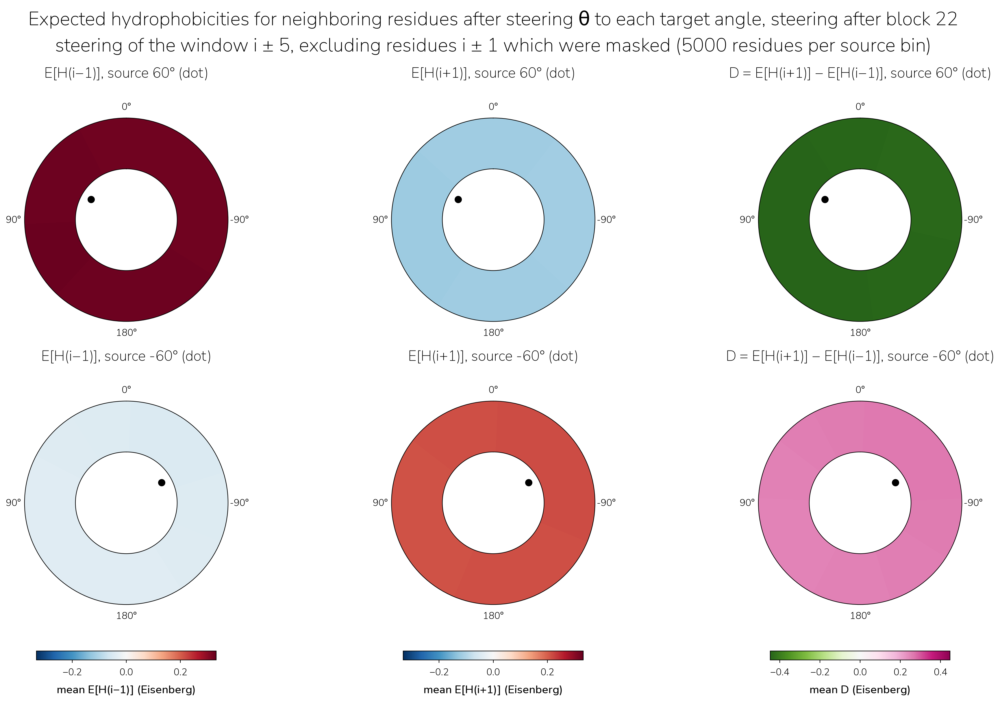

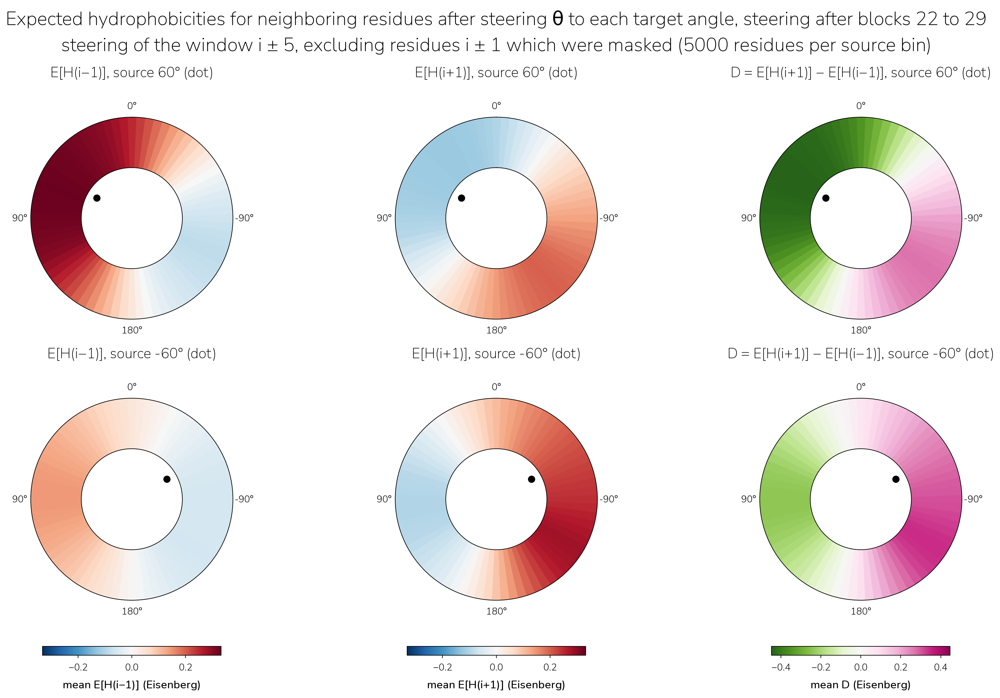

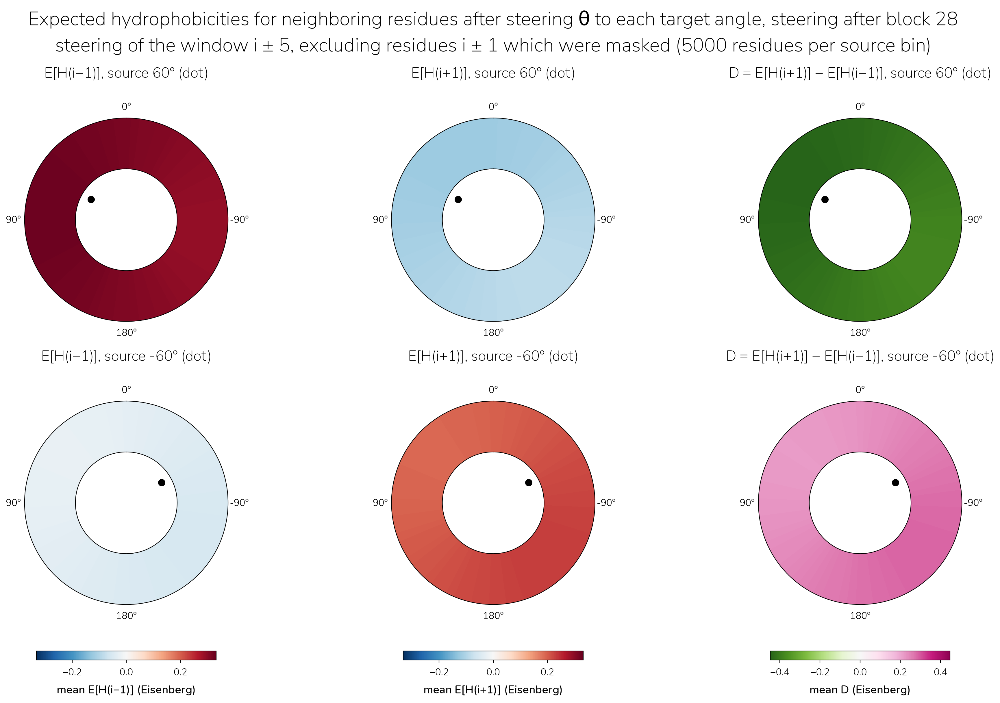

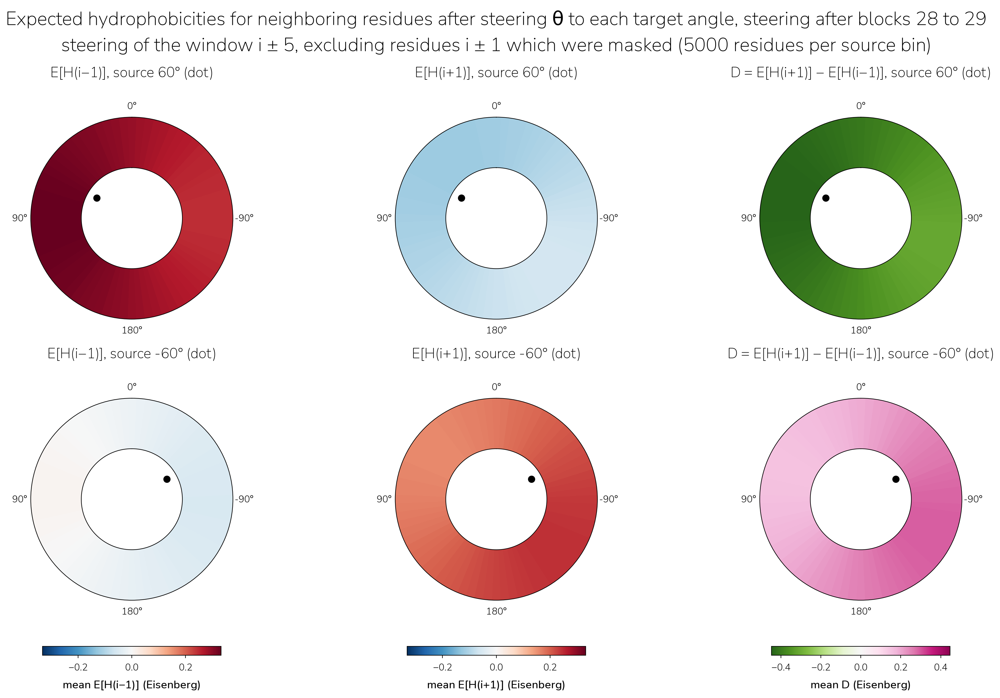

In [11]:
# the same colour scale in all the figures: one for the 2 E[H], one for D; centred on 0
targets = steer_summary.filter(pl.col("edit").str.starts_with("target"), pl.col("site") == f"i ± {N_MAX}")  # steering of the window
limits = {c: targets.select(pl.max_horizontal(pl.col(group).abs().max() for group in [["eh_before", "eh_after"], ["D"]] if c in group)).item() for c in METRICS.values()}


def steering_wheels(condition):
    """One wheel per source bin (rows) and metric (columns): the mean of the metric after steering of the window to each target."""
    fig, axes = plt.subplots(len(ANGLES), len(METRICS), figsize=(19, 12), subplot_kw={"projection": "polar"}, layout="constrained")
    for col, (metric, column) in zip(axes.T, METRICS.items()):
        norm, cmap = Normalize(-limits[column], limits[column]), NEIGHBOUR_DIFFERENCE if column == "D" else theme.HYDROPHOBICITY
        for ax, source in zip(col, ANGLES):
            d = targets.filter(pl.col("condition") == condition, pl.col("source_angle") == source).sort("x")
            ax.bar(np.deg2rad(d["x"].to_numpy()), 1, bottom=1, width=np.deg2rad(5), color=cmap(norm(d[column].to_numpy())), linewidth=0, antialiased=False)
            ax.plot(np.deg2rad(source), 0.8, marker="o", markersize=8, color="black")  # inside the ring, at the source angle
            theme.inner_border(ax)
            ax.set(rlim=(0, 2), yticks=[], theta_zero_location="N")  # 0 degrees at the top
            ax.set_thetagrids(range(0, 360, 90), ["0°", "90°", "180°", "-90°"])
            ax.grid(False)
            ax.set_title(f"{metric}, source {source}° (dot)", pad=28)  # above the 0° label
        fig.colorbar(ScalarMappable(norm, cmap), ax=col, shrink=0.5, location="bottom", label=f"mean {metric.split(' = ')[0]} (Eisenberg)")
    fig.suptitle(f"Expected hydrophobicities for neighboring residues after steering θ to each target angle, {after(condition).replace('ablation', 'steering')}\n"
                 f"steering of the window i ± {N_MAX}, excluding residues i ± 1 which were masked ({N_NEIGHBOURS} residues per source bin)", wrap=False)
    plt.show()


for condition in ["22", "22-29", "28", "28-29"]:
    steering_wheels(condition)
